<h3>By:Mahynour Ayman 222000300</h3>
<h3>Jana Emad 221003383</h3>
<h3>Mariam Ali 221003421</h3>

# Traffic Sign Detection & Recognition
Classical computer-vision pipeline: HSV colour segmentation → morphology → contour ROIs → HOG features → linear SVM.

Datasets are not included. See the README for download links and the folder layout.

In [1]:
# import necessary libraries
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import svm
from sklearn.metrics import classification_report, accuracy_score
from skimage.feature import hog
import time


## 1. Data: IJCNN 2013 scenes (GTSDB)
600 full road scenes (1360×800) with ground-truth sign boxes in `gt.txt`.

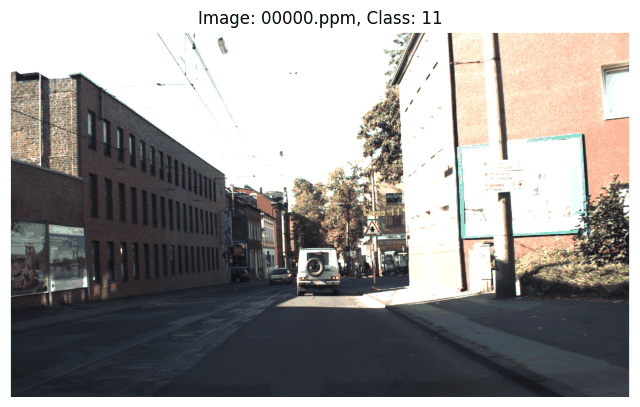

In [2]:
# Load annotation lines
with open('TrainIJCNN2013/gt.txt', 'r') as f:
    annotations = f.readlines()


# View one annotated image
sample = annotations[0].strip().split(';')

img_name = sample[0]
x1, y1, x2, y2 = map(int, sample[1:5])
class_id = sample[5]

# Load and convert the image
img_path = f'TrainIJCNN2013/{img_name}'
img = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Draw the bounding box
cv2.rectangle(img_rgb, (x1, y1), (x2, y2), (0, 255, 0), 2)
cv2.putText(img_rgb, f'Class {class_id}', (x1, y1-10),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 0), 2)

# Show the image
plt.figure(figsize=(8, 6))
plt.imshow(img_rgb)
plt.title(f"Image: {img_name}, Class: {class_id}")
plt.axis('off')
plt.show()

In [3]:
img_folder = 'TrainIJCNN2013'

# To store sizes
original_sizes = []

# Loop through images (for example first 5)
for idx, filename in enumerate(sorted(os.listdir(img_folder))):
    if filename.endswith(".ppm"):
        path = os.path.join(img_folder, filename)
        img = cv2.imread(path)
        original_sizes.append(img.shape[:2])  # (height, width)


        if idx < 16:  # print first 15 only
            print(f"Image: {filename}")
            print(f" Original size (HxW): {img.shape[:2]}")
        

Image: 00000.ppm
 Original size (HxW): (800, 1360)
Image: 00001.ppm
 Original size (HxW): (800, 1360)
Image: 00002.ppm
 Original size (HxW): (800, 1360)
Image: 00003.ppm
 Original size (HxW): (800, 1360)
Image: 00004.ppm
 Original size (HxW): (800, 1360)
Image: 00005.ppm
 Original size (HxW): (800, 1360)
Image: 00006.ppm
 Original size (HxW): (800, 1360)
Image: 00007.ppm
 Original size (HxW): (800, 1360)
Image: 00008.ppm
 Original size (HxW): (800, 1360)
Image: 00009.ppm
 Original size (HxW): (800, 1360)
Image: 00010.ppm
 Original size (HxW): (800, 1360)
Image: 00011.ppm
 Original size (HxW): (800, 1360)
Image: 00012.ppm
 Original size (HxW): (800, 1360)
Image: 00013.ppm
 Original size (HxW): (800, 1360)
Image: 00014.ppm
 Original size (HxW): (800, 1360)


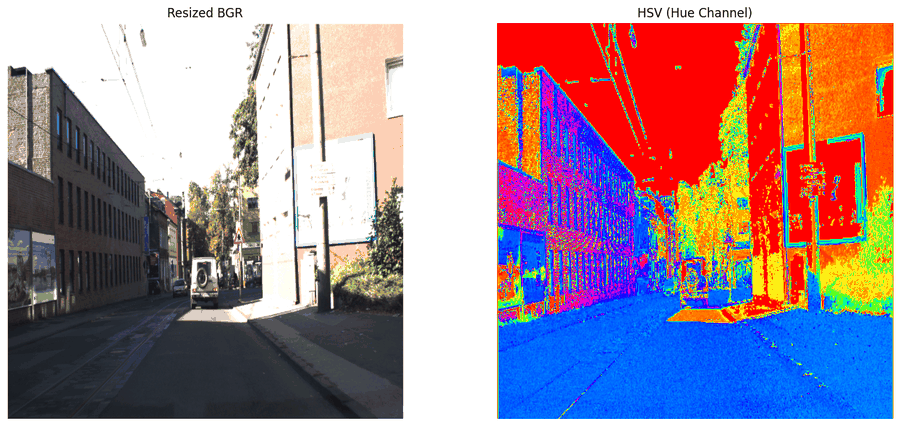

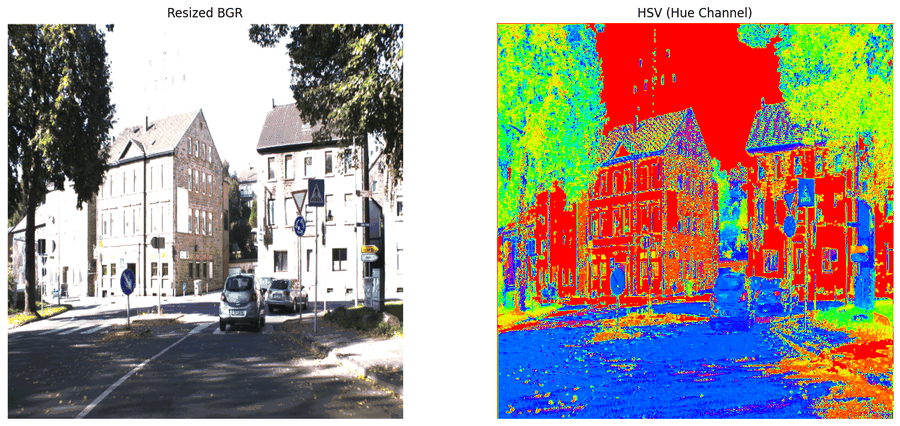

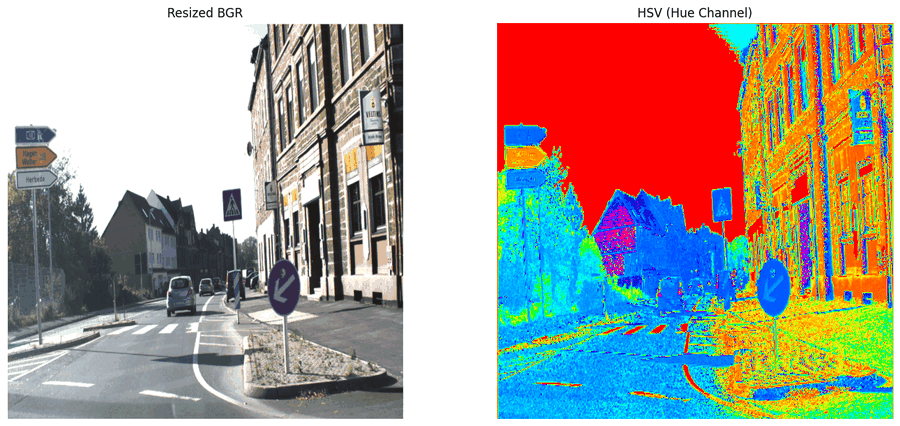

 Total images processed: 600


[2 more figures removed to keep the notebook small]


In [4]:
# Folder containing the images
img_folder = 'TrainIJCNN2013'

# Lists to store results
resized_images1 = []
hsv_images1 = []

# Loop through all .ppm files in the folder
for filename in sorted(os.listdir(img_folder)):
    if filename.endswith(".ppm"):
        img_path = os.path.join(img_folder, filename)
        img = cv2.imread(img_path)

        # Resize to 720x720
        resized = cv2.resize(img, (720, 720))

        # Convert from BGR to HSV
        hsv = cv2.cvtColor(resized, cv2.COLOR_BGR2HSV)

        # Store results
        resized_images1.append(resized)
        hsv_images1.append(hsv)

        # Show the first 3 for verification
        if len(resized_images1) <= 5:
            plt.figure(figsize=(14, 6))

            plt.subplot(1, 2, 1)
            plt.imshow(cv2.cvtColor(resized, cv2.COLOR_BGR2RGB))
            plt.title("Resized BGR")
            plt.axis("off")

            plt.subplot(1, 2, 2)
            plt.imshow(hsv[:, :, 0], cmap='hsv')  # Show only Hue channel for clarity
            plt.title("HSV (Hue Channel)")
            plt.axis("off")

            plt.tight_layout()
            plt.show()

print(f" Total images processed: {len(resized_images1)}")


## 2. Pre-processing
Resize to 720×720, convert to HSV, and equalise the V (brightness) channel so the colour thresholds are less sensitive to lighting.

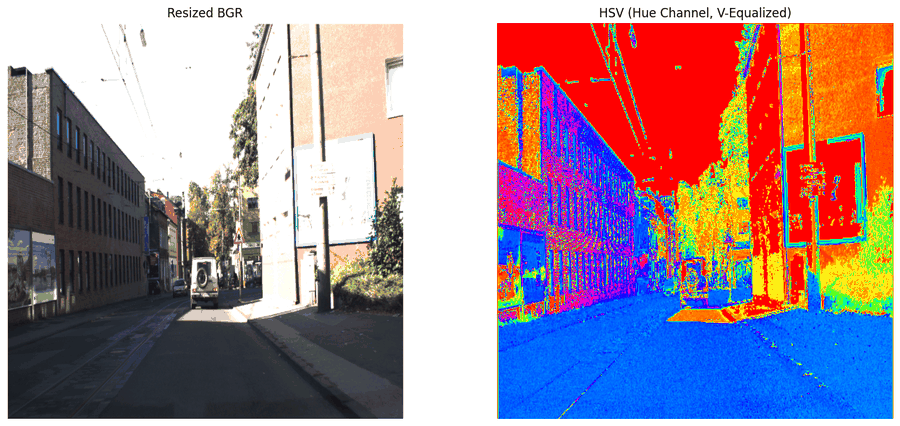

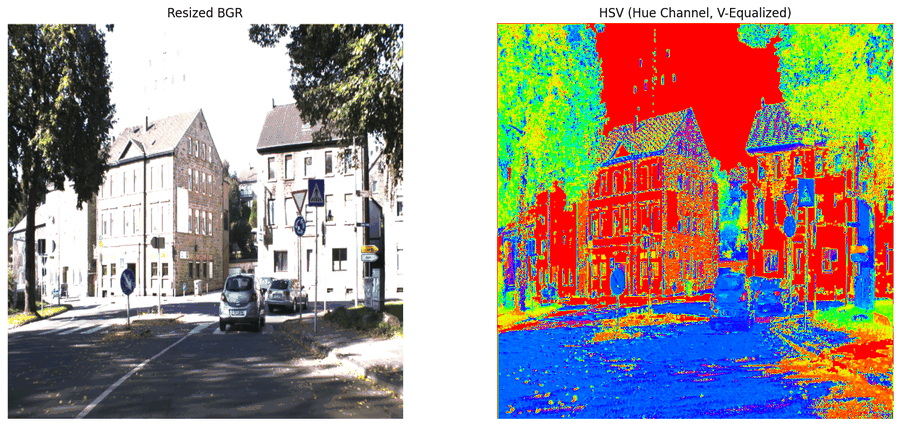

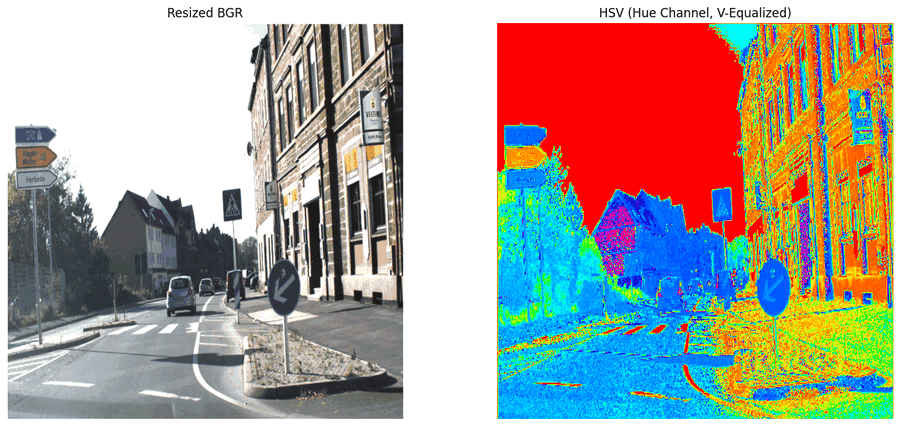

 Total images processed: 600


[2 more figures removed to keep the notebook small]


In [5]:

# Folder containing the images
img_folder = 'TrainIJCNN2013'

# Lists to store results
resized_images = []
hsv_images = []

# Loop through all .ppm files in the folder
for filename in sorted(os.listdir(img_folder)):
    if filename.endswith(".ppm"):
        img_path = os.path.join(img_folder, filename)
        img = cv2.imread(img_path)

        # Resize to 720x720
        resized = cv2.resize(img, (720, 720))

        # Convert from BGR to HSV
        hsv = cv2.cvtColor(resized, cv2.COLOR_BGR2HSV)

        # Split channels
        h, s, v = cv2.split(hsv)

        # Apply histogram equalization to the V channel
        v_eq = cv2.equalizeHist(v)

        # Merge back the equalized HSV
        hsv_eq = cv2.merge((h, s, v_eq))

        # Store results
        resized_images.append(resized)
        hsv_images.append(hsv_eq)

        # Show the first 5 for verification
        if len(resized_images) <= 5:
            plt.figure(figsize=(14, 6))

            plt.subplot(1, 2, 1)
            plt.imshow(cv2.cvtColor(resized, cv2.COLOR_BGR2RGB))
            plt.title("Resized BGR")
            plt.axis("off")

            plt.subplot(1, 2, 2)
            plt.imshow(hsv_eq[:, :, 0], cmap='hsv')  # Hue channel (after V equalization)
            plt.title("HSV (Hue Channel, V-Equalized)")
            plt.axis("off")

            plt.tight_layout()
            plt.show()

print(f" Total images processed: {len(resized_images)}")


In [6]:
print(np.unique(hsv[:, :, 0]))


[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
 162 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179]


## 3. Colour segmentation
Traffic signs are mostly red or blue. Two red hue ranges (red wraps around 0/180) and one blue range give binary masks.

In [7]:
lower_red1 = np.array([0, 30, 30])
upper_red1 = np.array([10, 255, 255])
lower_red2 = np.array([170, 30, 30])
upper_red2 = np.array([180, 255, 255])
lower_blue = np.array([90, 30, 30])
upper_blue = np.array([140, 255, 255])
red_masks = []
blue_masks = []
combined_masks = []
for hsv in hsv_images:
    h, s, v = cv2.split(hsv)

    # Create a mask to keep only sufficiently saturated and bright pixels
    sat_val_mask = cv2.inRange(hsv, (0, 30, 40), (179, 255, 255))

   
    # Red masks
    mask_red1 = cv2.inRange(hsv, lower_red1, upper_red1)
    mask_red2 = cv2.inRange(hsv, lower_red2, upper_red2)
    mask_red = cv2.bitwise_or(mask_red1, mask_red2)

    # Blue mask
    mask_blue = cv2.inRange(hsv, lower_blue, upper_blue)

    # Apply saturation and brightness mask
    mask_red = cv2.bitwise_and(mask_red, sat_val_mask)
    mask_blue = cv2.bitwise_and(mask_blue, sat_val_mask)

    # Combine red and blue masks
    mask_combined = cv2.bitwise_or(mask_red, mask_blue)

    red_masks.append(mask_red)
    blue_masks.append(mask_blue)
    combined_masks.append(mask_combined)
print(f'Applied red and blue filters on {len(hsv_images)} images.')

Applied red and blue filters on 600 images.


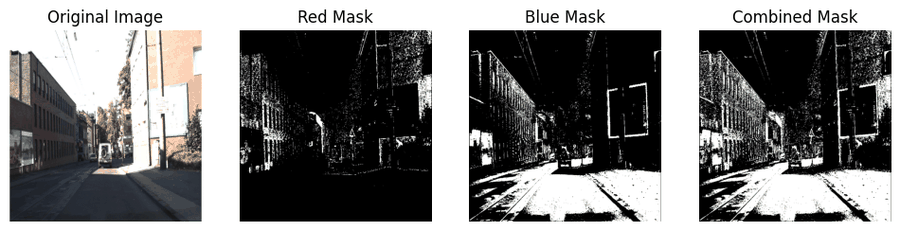

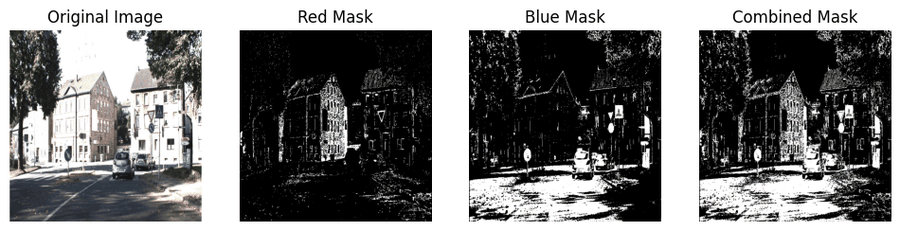

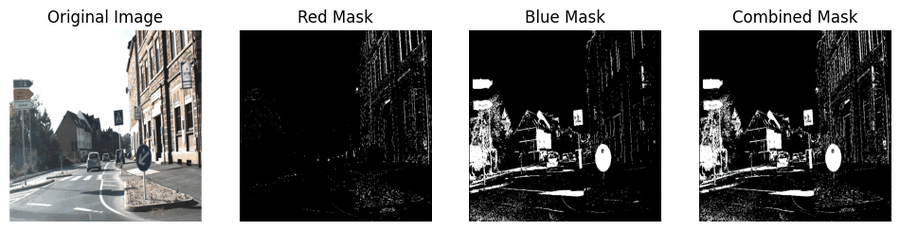

[12 more figures removed to keep the notebook small]


In [8]:
# Number of images to visualize
num_samples = 15

for i in range(num_samples):
    # Convert original BGR image to RGB for correct color display in matplotlib
    rgb_img = cv2.cvtColor(resized_images[i], cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12,4))

    plt.subplot(1,4,1)
    plt.imshow(rgb_img)
    plt.title('Original Image')
    plt.axis('off')

    plt.subplot(1,4,2)
    plt.imshow(red_masks[i], cmap='gray')
    plt.title('Red Mask')
    plt.axis('off')

    plt.subplot(1,4,3)
    plt.imshow(blue_masks[i], cmap='gray')
    plt.title('Blue Mask')
    plt.axis('off')

    plt.subplot(1,4,4)
    plt.imshow(combined_masks[i], cmap='gray')
    plt.title('Combined Mask')
    plt.axis('off')

    plt.show()

mask is a binary image  single-channel grayscale:

Shape: (height, width)

Pixel values: 0 (black → outside range), 255 (white → inside range)

Data type: uint8

So after filtering, the images (masks) are:

 Grayscale binary masks

In [9]:
# Opens desktop windows (blocks inside Jupyter), so it is commented out. The matplotlib cells show the same images.
# import cv2
# 
# for i in range(3):  # show first 3 images
#     # Show the original image
#     cv2.imshow(f'Original Image {i}', resized_images[i])
#     
#     # Show the combined mask (it's single channel, so show as is)
#     cv2.imshow(f'Combined Mask {i}', combined_masks[i])
#     
#     cv2.waitKey(0)  # wait until a key is pressed to move to next image
#     cv2.destroyAllWindows()  # close all windows before next iteration

## 4. Morphological clean-up
Opening removes speckle noise; closing fills small holes inside sign shapes.

In [10]:
def morphological_opening(mask, kernel_size=(2,2)):
    kernel = np.ones(kernel_size, np.uint8)
    return cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

opened_masks = [morphological_opening(mask) for mask in combined_masks]

print("Morphological opening applied.")

Morphological opening applied.


In [11]:
def morphological_closing(mask, kernel_size=(3,3)):
    kernel = np.ones(kernel_size, np.uint8)
    return cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

closed_masks = [morphological_closing(mask) for mask in opened_masks]

print("Morphological closing applied.")


Morphological closing applied.


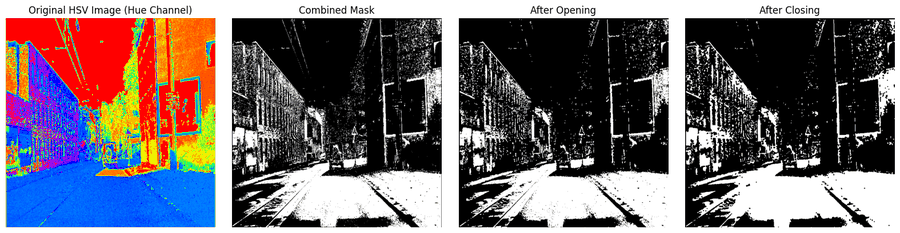

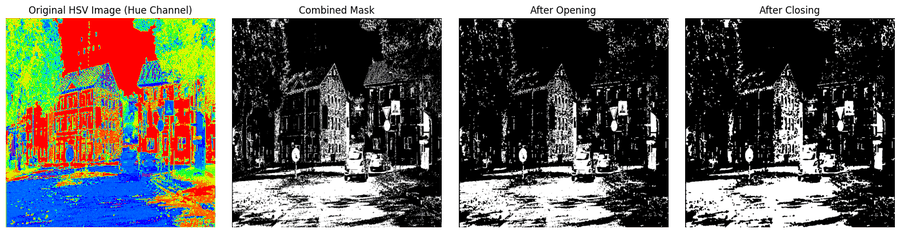

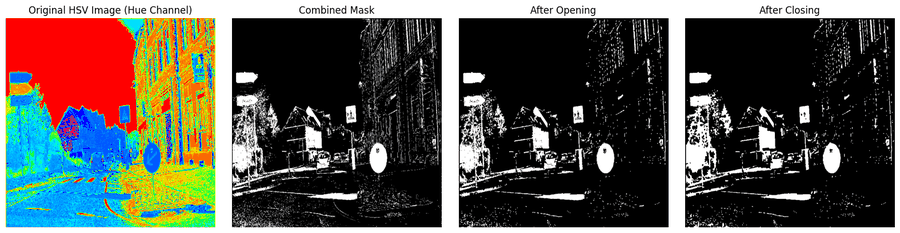

[12 more figures removed to keep the notebook small]


In [12]:
for i in range(min(15, len(hsv_images))):
    plt.figure(figsize=(16, 4))
    
    plt.subplot(1, 4, 1)
    plt.title("Original HSV Image (Hue Channel)")
    plt.imshow(hsv_images[i][:,:,0], cmap='hsv')
    plt.axis('off')
    
    plt.subplot(1, 4, 2)
    plt.title("Combined Mask")
    plt.imshow(combined_masks[i], cmap='gray')
    plt.axis('off')
    
    plt.subplot(1, 4, 3)
    plt.title("After Opening")
    plt.imshow(opened_masks[i], cmap='gray')
    plt.axis('off')
    
    plt.subplot(1, 4, 4)
    plt.title("After Closing")
    plt.imshow(closed_masks[i], cmap='gray')
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()


## 5. Region proposals from contours
Contours with a plausible area become candidate sign regions (ROIs).

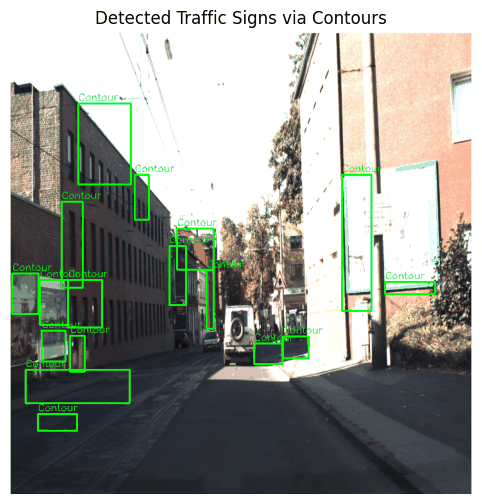

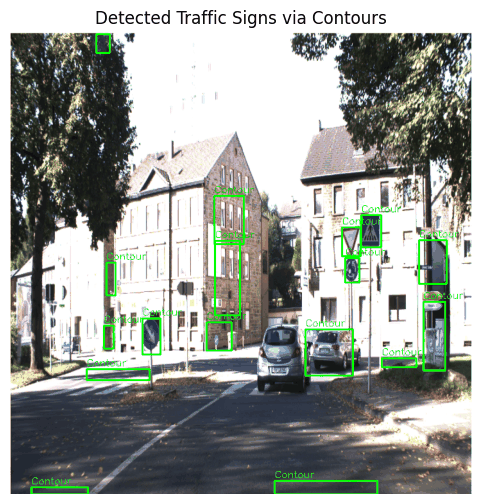

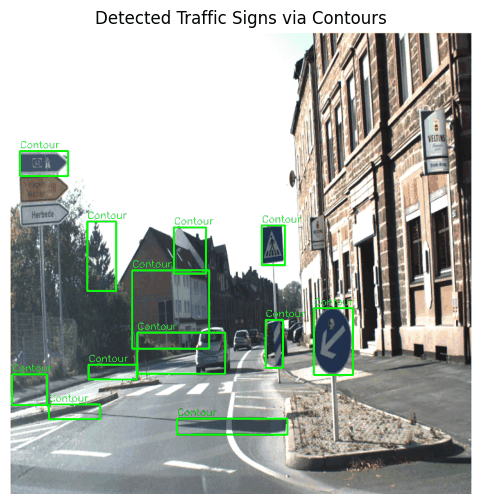

[12 more figures removed to keep the notebook small]


In [13]:

contour_bboxes_images = []

for img, mask in zip(resized_images, opened_masks):
    img_copy = img.copy()

    # Find contours in the mask
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    for cnt in contours:
        area = cv2.contourArea(cnt)
        
        # Filter out very small or very large areas (tweak thresholds as needed)
        if 300 < area < 5000:
            x, y, w, h = cv2.boundingRect(cnt)
            cv2.rectangle(img_copy, (x, y), (x + w, y + h), (0, 255, 0), 2)
            cv2.putText(img_copy, 'Contour', (x, y - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)

    contour_bboxes_images.append(img_copy)

# Visualize a few results
num_samples = 15
for i in range(num_samples):
    plt.figure(figsize=(10, 6))
    plt.imshow(cv2.cvtColor(contour_bboxes_images[i], cv2.COLOR_BGR2RGB))
    plt.title("Detected Traffic Signs via Contours")
    plt.axis('off')
    plt.show()


In [14]:
rois = []
rois_bboxes = []  # Store bounding boxes

for img, mask in zip(resized_images, closed_masks):
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    for cnt in contours:
        area = cv2.contourArea(cnt)
        if area < 300:
            continue

        perimeter = cv2.arcLength(cnt, True)
        approx = cv2.approxPolyDP(cnt, 0.04 * perimeter, True)
        x, y, w, h = cv2.boundingRect(approx)

        roi = img[y:y+h, x:x+w]
        if roi.shape[0] > 0 and roi.shape[1] > 0:
            rois.append(roi)
            rois_bboxes.append((x, y, w, h))  # Save the bounding box


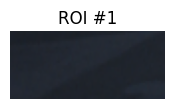

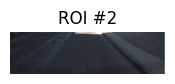

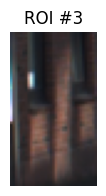

[22 more figures removed to keep the notebook small]


In [15]:

# Show first 10 extracted ROIs
for i in range(min(25, len(rois))):
    plt.figure(figsize=(2, 2))
    plt.imshow(cv2.cvtColor(rois[i], cv2.COLOR_BGR2RGB))
    plt.title(f"ROI #{i+1}")
    plt.axis('off')
    plt.show()


In [16]:
print(f"Total ROIs extracted: {len(rois)}")

# Optional: print sizes of the first few ROIs
for i, roi in enumerate(rois[:50]):
    print(f"ROI {i} size: {roi.shape}")  # (height, width, channels)

Total ROIs extracted: 6093
ROI 0 size: (34, 78, 3)
ROI 1 size: (190, 701, 3)
ROI 2 size: (62, 35, 3)
ROI 3 size: (64, 36, 3)
ROI 4 size: (23, 21, 3)
ROI 5 size: (53, 16, 3)
ROI 6 size: (77, 116, 3)
ROI 7 size: (70, 87, 3)
ROI 8 size: (36, 21, 3)
ROI 9 size: (47, 59, 3)
ROI 10 size: (176, 59, 3)
ROI 11 size: (244, 166, 3)
ROI 12 size: (230, 42, 3)
ROI 13 size: (204, 119, 3)
ROI 14 size: (67, 43, 3)
ROI 15 size: (222, 168, 3)
ROI 16 size: (49, 24, 3)
ROI 17 size: (52, 19, 3)
ROI 18 size: (14, 135, 3)
ROI 19 size: (90, 615, 3)
ROI 20 size: (53, 100, 3)
ROI 21 size: (38, 192, 3)
ROI 22 size: (33, 32, 3)
ROI 23 size: (48, 15, 3)
ROI 24 size: (65, 28, 3)
ROI 25 size: (106, 30, 3)
ROI 26 size: (43, 40, 3)
ROI 27 size: (95, 8, 3)
ROI 28 size: (81, 48, 3)
ROI 29 size: (42, 31, 3)
ROI 30 size: (64, 64, 3)
ROI 31 size: (24, 67, 3)
ROI 32 size: (293, 356, 3)
ROI 33 size: (29, 24, 3)
ROI 34 size: (11, 240, 3)
ROI 35 size: (32, 145, 3)
ROI 36 size: (65, 134, 3)
ROI 37 size: (107, 61, 3)
ROI 38 size:

In [17]:
rois = []
rois_bboxes = []

for img, mask in zip(resized_images, closed_masks):
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    for cnt in contours:
        area = cv2.contourArea(cnt)
        if area < 300:
            continue

        perimeter = cv2.arcLength(cnt, True)
        approx = cv2.approxPolyDP(cnt, 0.04 * perimeter, True)
        x, y, w, h = cv2.boundingRect(approx)

        roi = img[y:y+h, x:x+w]
        if roi.shape[0] > 0 and roi.shape[1] > 0:
            rois.append(roi)
            rois_bboxes.append((x, y, w, h))

# Filter tiny ROIs before resizing
num_original = len(rois)
filtered_rois = []
filtered_bboxes = []

for roi, bbox in zip(rois, rois_bboxes):
    if roi.shape[0] > 30 and roi.shape[1] > 20:
        filtered_rois.append(roi)
        filtered_bboxes.append(bbox)

num_filtered = len(filtered_rois)
num_removed = num_original - num_filtered

print(f"Original ROI count: {num_original}")
print(f"Filtered ROI count (kept): {num_filtered}")
print(f"Removed tiny ROIs: {num_removed}")

# Resize filtered ROIs for further processing
resized_rois = [cv2.resize(roi, (32, 32)) for roi in filtered_rois]


Original ROI count: 6093
Filtered ROI count (kept): 4462
Removed tiny ROIs: 1631


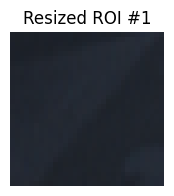

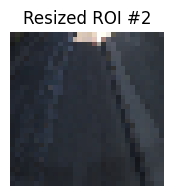

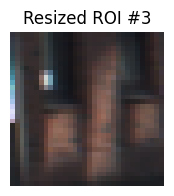

[12 more figures removed to keep the notebook small]


In [18]:
for i in range(min(15, len(resized_rois))):
    plt.figure(figsize=(2, 2))
    plt.imshow(cv2.cvtColor(resized_rois[i], cv2.COLOR_BGR2RGB))
    plt.title(f"Resized ROI #{i+1}")
    plt.axis('off')
    plt.show()

In [19]:
for i, roi in enumerate(resized_rois[:50]):
    print(f"ROI {i} size: {roi.shape}")  # (height, width, channels)

ROI 0 size: (32, 32, 3)
ROI 1 size: (32, 32, 3)
ROI 2 size: (32, 32, 3)
ROI 3 size: (32, 32, 3)
ROI 4 size: (32, 32, 3)
ROI 5 size: (32, 32, 3)
ROI 6 size: (32, 32, 3)
ROI 7 size: (32, 32, 3)
ROI 8 size: (32, 32, 3)
ROI 9 size: (32, 32, 3)
ROI 10 size: (32, 32, 3)
ROI 11 size: (32, 32, 3)
ROI 12 size: (32, 32, 3)
ROI 13 size: (32, 32, 3)
ROI 14 size: (32, 32, 3)
ROI 15 size: (32, 32, 3)
ROI 16 size: (32, 32, 3)
ROI 17 size: (32, 32, 3)
ROI 18 size: (32, 32, 3)
ROI 19 size: (32, 32, 3)
ROI 20 size: (32, 32, 3)
ROI 21 size: (32, 32, 3)
ROI 22 size: (32, 32, 3)
ROI 23 size: (32, 32, 3)
ROI 24 size: (32, 32, 3)
ROI 25 size: (32, 32, 3)
ROI 26 size: (32, 32, 3)
ROI 27 size: (32, 32, 3)
ROI 28 size: (32, 32, 3)
ROI 29 size: (32, 32, 3)
ROI 30 size: (32, 32, 3)
ROI 31 size: (32, 32, 3)
ROI 32 size: (32, 32, 3)
ROI 33 size: (32, 32, 3)
ROI 34 size: (32, 32, 3)
ROI 35 size: (32, 32, 3)
ROI 36 size: (32, 32, 3)
ROI 37 size: (32, 32, 3)
ROI 38 size: (32, 32, 3)
ROI 39 size: (32, 32, 3)
ROI 40 siz

## 6. Classifier training data: GTSRB
39,209 cropped sign images in 43 classes, resized to 32×32.

In [20]:
# Path to the GTSRB Final_Training folder
train_dir = "Final_Training/Images"

images = []
labels = []

# Loop through each class folder (00000 to 00042)
for class_id in sorted(os.listdir(train_dir)):
    class_folder = os.path.join(train_dir, class_id)
    if os.path.isdir(class_folder):
        # Loop through each image file in the class folder
        for filename in os.listdir(class_folder):
            if filename.endswith(".ppm") or filename.endswith(".png") or filename.endswith(".jpg"):
                img_path = os.path.join(class_folder, filename)
                img = cv2.imread(img_path)
                if img is not None:
                    images.append(img)
                    labels.append(int(class_id))

print(f"Loaded {len(images)} images from GTSRB training set.")


Loaded 39209 images from GTSRB training set.


In [21]:
from collections import Counter

sizes = [img.shape[:2] for img in images]  # (height, width)
size_counts = Counter(sizes)
print("Image sizes and counts:", size_counts)


Image sizes and counts: Counter({(31, 31): 396, (30, 30): 380, (35, 35): 360, (32, 32): 352, (33, 33): 351, (38, 38): 345, (34, 34): 339, (29, 29): 338, (31, 30): 337, (36, 36): 334, (33, 32): 326, (34, 33): 318, (37, 37): 310, (30, 29): 297, (40, 40): 297, (35, 34): 280, (32, 31): 276, (36, 35): 273, (43, 43): 265, (28, 28): 263, (33, 34): 262, (39, 39): 262, (37, 36): 262, (41, 41): 259, (39, 38): 249, (29, 28): 247, (30, 31): 243, (40, 39): 238, (38, 37): 229, (41, 40): 229, (34, 35): 229, (31, 32): 228, (32, 33): 222, (36, 37): 210, (42, 42): 210, (29, 30): 204, (37, 38): 199, (35, 36): 196, (27, 27): 194, (28, 27): 193, (44, 44): 188, (38, 39): 183, (42, 41): 177, (39, 40): 174, (28, 29): 173, (40, 41): 161, (46, 46): 161, (43, 42): 160, (32, 30): 158, (45, 45): 158, (48, 48): 156, (45, 44): 147, (41, 42): 147, (47, 47): 145, (36, 34): 144, (42, 43): 143, (47, 46): 142, (33, 31): 136, (52, 52): 135, (27, 28): 134, (49, 49): 133, (44, 43): 129, (31, 29): 125, (43, 44): 125, (46, 45

In [22]:
resized_gtsrb_images = []

for img in images:  # assuming gtsrb_images is your list of loaded images
    resized_img3 = cv2.resize(img, (32, 32))
    resized_gtsrb_images.append(resized_img3)
    
print(f"Resized {len(resized_gtsrb_images)} GTSRB training images to 32x32.")

Resized 39209 GTSRB training images to 32x32.


In [23]:
sizes = [img.shape[:3] for img in resized_gtsrb_images]
print("Image sizes :", sizes)

Image sizes : [(32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3), (32, 32, 3

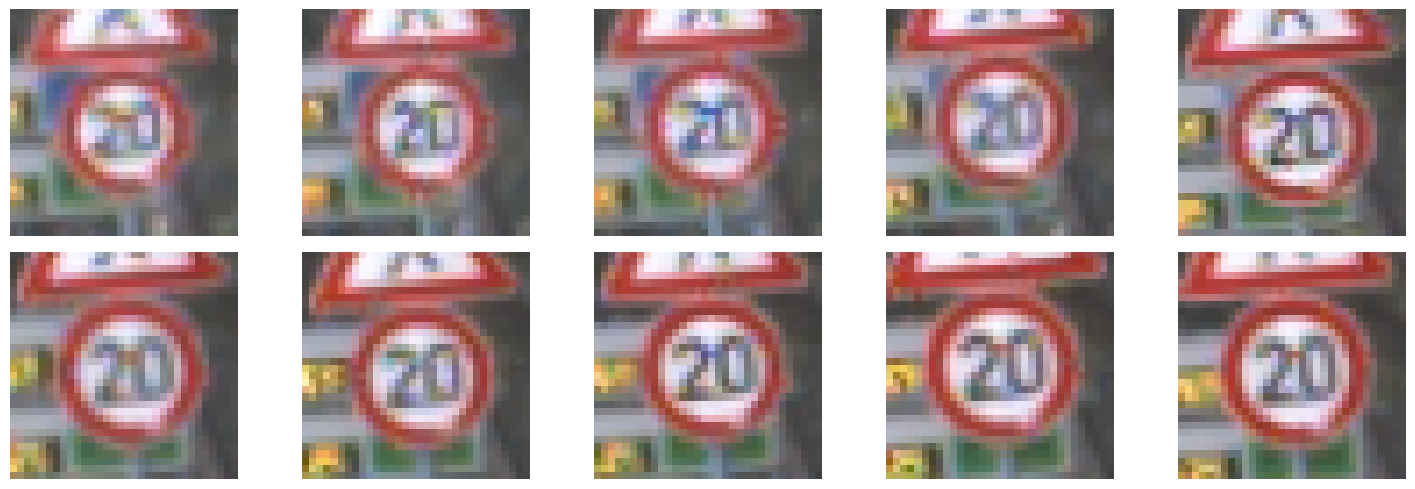

In [24]:
num_to_show = 10
plt.figure(figsize=(15, 5))

for i in range(num_to_show):
    plt.subplot(2, 5, i + 1)
    plt.imshow(cv2.cvtColor(resized_gtsrb_images[i], cv2.COLOR_BGR2RGB))
    plt.axis('off')

plt.tight_layout()
plt.show()

In [25]:

img_folder = 'Final_Test/Images'

# To store sizes
original_sizes_test = []

# Loop through images (for example first 5)
for idx, filename in enumerate(sorted(os.listdir(img_folder))):
    if filename.endswith(".ppm"):
        path = os.path.join(img_folder, filename)
        img = cv2.imread(path)
        original_sizes_test .append(img.shape[:2])  # (height, width)


        if idx < 16:  # print first 15 only
            print(f"Image: {filename}")
            print(f" Original size (HxW): {img.shape[:2]}")


Image: 00000.ppm
 Original size (HxW): (54, 53)
Image: 00001.ppm
 Original size (HxW): (45, 42)
Image: 00002.ppm
 Original size (HxW): (52, 48)
Image: 00003.ppm
 Original size (HxW): (29, 27)
Image: 00004.ppm
 Original size (HxW): (57, 60)
Image: 00005.ppm
 Original size (HxW): (56, 52)
Image: 00006.ppm
 Original size (HxW): (130, 147)
Image: 00007.ppm
 Original size (HxW): (33, 32)
Image: 00008.ppm
 Original size (HxW): (50, 45)
Image: 00009.ppm
 Original size (HxW): (86, 81)
Image: 00010.ppm
 Original size (HxW): (37, 38)
Image: 00011.ppm
 Original size (HxW): (44, 45)
Image: 00012.ppm
 Original size (HxW): (73, 79)
Image: 00013.ppm
 Original size (HxW): (37, 36)
Image: 00014.ppm
 Original size (HxW): (41, 43)
Image: 00015.ppm
 Original size (HxW): (27, 27)


In [26]:
# import cv2

# def convert_to_grayscale(images):
#     gray_images = [cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) for img in images]
#     return gray_images
# # Assuming test_images contains loaded color images
# test_images_gray = convert_to_grayscale(test_images)
# print(f"Converted {len(test_images_gray)} test images to grayscale.")


## 7. HOG features + linear SVM
Histogram-of-oriented-gradients (324-d) on the grayscale crop, classified with a linear SVM.

In [27]:
from skimage.feature import hog
import numpy as np

X_train = []
y_train = []

for img, label in zip(resized_gtsrb_images, labels):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    features = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm='L2-Hys',
        feature_vector=True
    )
    X_train.append(features)
    y_train.append(label)

X_train = np.array(X_train)
y_train = np.array(y_train)

print(f"Extracted HOG features for {len(X_train)} images.")
print(f"Feature vector shape: {X_train.shape}")
print(f"Number of labels: {len(y_train)}")


Extracted HOG features for 39209 images.
Feature vector shape: (39209, 324)
Number of labels: 39209


In [28]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score

# Initialize the SVM classifier
svm_clf = LinearSVC(max_iter=10000, random_state=42)

# Train the classifier on the training data
svm_clf.fit(X_train, y_train)

# Predict on training set to check accuracy
y_train_pred = svm_clf.predict(X_train)
train_acc = accuracy_score(y_train, y_train_pred)

print(f"Training accuracy: {train_acc:.4f}")


Training accuracy: 0.9153


In [29]:


test_img_folder = 'Final_Test/Images'
resized_test_images = []

for filename in sorted(os.listdir(test_img_folder)):
    if filename.endswith(".ppm"):
        img_path = os.path.join(test_img_folder, filename)
        img = cv2.imread(img_path)
        if img is not None:
            resized_img = cv2.resize(img, (32, 32))
            gray_img = cv2.cvtColor(resized_img, cv2.COLOR_BGR2GRAY)
            resized_test_images.append(gray_img)

print(f"Resized and converted {len(resized_test_images)} test images to grayscale 32x32.")


Resized and converted 12630 test images to grayscale 32x32.


In [30]:
from skimage.feature import hog
import numpy as np

test_hog_features = []

for gray_img in resized_test_images:
    features = hog(gray_img, orientations=9, pixels_per_cell=(8, 8), 
                   cells_per_block=(2, 2), block_norm='L2-Hys', visualize=False)
    test_hog_features.append(features)

X_test = np.array(test_hog_features)
print(f"Extracted HOG features from {X_test.shape[0]} test images.")


Extracted HOG features from 12630 test images.


In [31]:
# Assuming svm_clf is  trained SVM classifier from previous steps
y_test_pred = svm_clf.predict(X_test)
print(f"Predicted classes for {len(y_test_pred)} test images.")


Predicted classes for 12630 test images.


## 8. Test-set evaluation (12,630 images)

In [32]:
import pandas as pd

# Path to GT-final.csv
gt_path = 'GT-final_test.csv'

# Load ground truth CSV
gt_df = pd.read_csv(gt_path, sep=';')

# Check first few rows
print(gt_df.head())

# Create dictionary mapping filename to classId
gt_labels = dict(zip(gt_df['Filename'], gt_df['ClassId']))


    Filename  Width  Height  Roi.X1  Roi.Y1  Roi.X2  Roi.Y2  ClassId
0  00000.ppm     53      54       6       5      48      49       16
1  00001.ppm     42      45       5       5      36      40        1
2  00002.ppm     48      52       6       6      43      47       38
3  00003.ppm     27      29       5       5      22      24       33
4  00004.ppm     60      57       5       5      55      52       11


In [33]:
test_filenames = sorted([f for f in os.listdir(test_img_folder) if f.endswith(".ppm")])
print(f"Total test filenames: {len(test_filenames)}")
print("Sample filenames:", test_filenames[:5])


Total test filenames: 12630
Sample filenames: ['00000.ppm', '00001.ppm', '00002.ppm', '00003.ppm', '00004.ppm']


In [34]:
y_true = [gt_labels[filename] for filename in test_filenames]
print(f"Mapped {len(y_true)} ground truth labels from filenames.")


Mapped 12630 ground truth labels from filenames.


In [35]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Compute accuracy
acc = accuracy_score(y_true, y_test_pred)
print(f"Test accuracy: {acc:.4f}")

# Classification report
print(classification_report(y_true, y_test_pred))



Test accuracy: 0.7915
              precision    recall  f1-score   support

           0       0.58      0.65      0.61        60
           1       0.60      0.62      0.61       720
           2       0.68      0.73      0.70       750
           3       0.58      0.66      0.62       450
           4       0.89      0.93      0.91       660
           5       0.57      0.56      0.56       630
           6       0.85      0.73      0.79       150
           7       0.79      0.72      0.76       450
           8       0.71      0.68      0.70       450
           9       0.85      0.84      0.84       480
          10       0.88      0.95      0.91       660
          11       0.68      0.64      0.66       420
          12       0.96      0.97      0.97       690
          13       0.99      1.00      0.99       720
          14       0.91      0.83      0.87       270
          15       0.85      0.93      0.89       210
          16       0.99      0.91      0.94       150
     

In [36]:

roi_hog_features = []

for roi_img in resized_rois:  
    gray_roi = cv2.cvtColor(roi_img, cv2.COLOR_BGR2GRAY)  # convert to grayscale if not already
    features = hog(gray_roi, orientations=9, pixels_per_cell=(8, 8),
                   cells_per_block=(2, 2), block_norm='L2-Hys', visualize=False)
    roi_hog_features.append(features)

X_rois = np.array(roi_hog_features)


In [37]:
# Opens desktop windows (blocks inside Jupyter), so it is commented out. The matplotlib cells show the same images.
# 
# for i_img, img in enumerate(resized_images):
#     mask = closed_masks[i_img]
#     contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
# 
#     rois = []
#     bboxes = []
# 
#     # Extract and filter ROIs before resizing
#     for cnt in contours:
#         area = cv2.contourArea(cnt)
#         if area < 300:
#             continue  # skip small contours
# 
#         x, y, w, h = cv2.boundingRect(cnt)
#         if w < 20 or h < 30:
#             continue  # filter tiny ROIs by width and height
# 
#         roi = img[y:y+h, x:x+w]
#         if roi.shape[0] > 0 and roi.shape[1] > 0:
#             rois.append(roi)
#             bboxes.append((x, y, w, h))
# 
#     # Resize ROIs to 32x32
#     resized_rois = [cv2.resize(roi, (32, 32)) for roi in rois]
# 
#     # Convert to grayscale
#     gray_rois = [cv2.cvtColor(r, cv2.COLOR_BGR2GRAY) for r in resized_rois]
# 
#     # Extract HOG features
#     hog_features = [hog(img_gray, orientations=9, pixels_per_cell=(8,8),
#                         cells_per_block=(2,2), block_norm='L2-Hys', visualize=False)
#                     for img_gray in gray_rois]
# 
#     if len(hog_features) == 0:
#         continue  # no ROIs left after filtering
# 
#     X_rois = np.array(hog_features)
# 
#     # Predict classes and get confidence scores
#     predicted_classes = svm_clf.predict(X_rois)
#     decision_scores = svm_clf.decision_function(X_rois)
#     max_scores = np.max(decision_scores, axis=1)
#     
#     
#     # Annotate the image with bounding boxes and labels
#     for bbox, cls, score in zip(bboxes, predicted_classes, max_scores):
#         x, y, w, h = bbox
#         cv2.rectangle(img, (x, y), (x + w, y + h), (200, 0, 0), 2)
#         label = f"Class {cls}: {score:.2f}"
#         cv2.putText(img, label, (x, y - 10),
#                     cv2.FONT_HERSHEY_SIMPLEX, 0.5, (200, 0, 0), 1)
# 
#     # Optionally: display or save the annotated image here
#     # cv2.imshow(f"Annotated Image {i_img}", img)
#     # cv2.waitKey(0)
#     # cv2.destroyAllWindows()

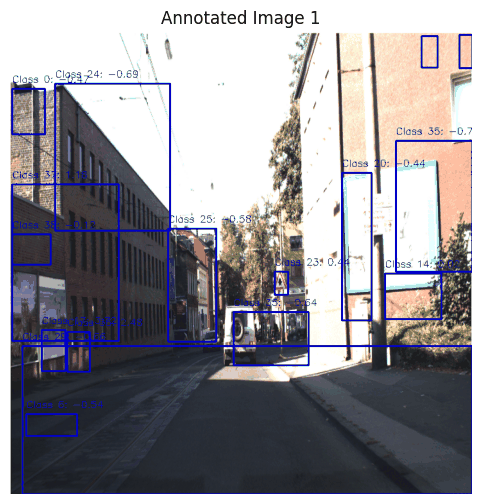

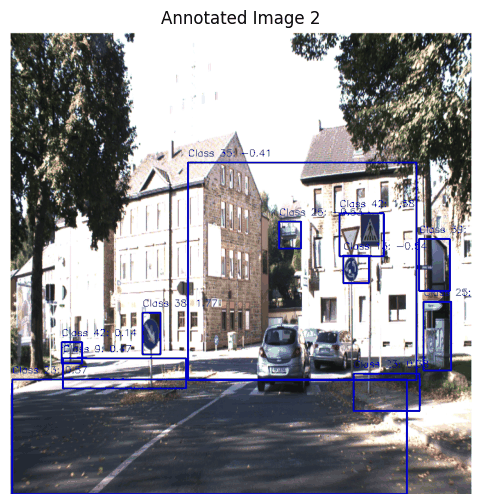

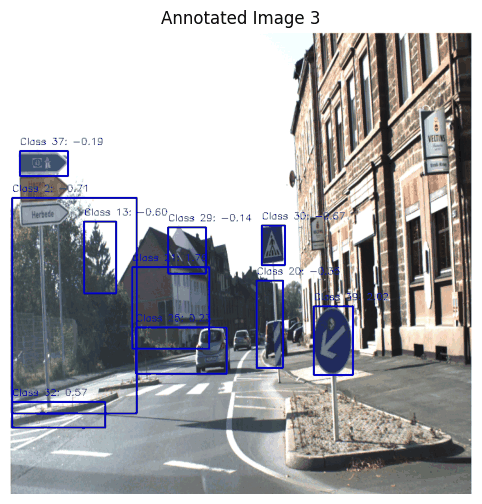

[2 more figures removed to keep the notebook small]


In [38]:
import matplotlib.pyplot as plt

# Display first 5 annotated images
for i in range(min(5, len(resized_images))):
    img = resized_images[i]

    # Convert BGR to RGB for correct color display in matplotlib
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8,6))
    plt.imshow(img_rgb)
    plt.title(f"Annotated Image {i+1}")
    plt.axis('off')
    plt.show()


In [39]:

import pandas as pd

# Path to your gt.txt file
gt_file = 'TrainIJCNN2013/gt.txt'

# Read using correct delimiter
gt_df = pd.read_csv(gt_file, sep=';', header=None)

# Assign proper column names
gt_df.columns = ['Filename', 'xmin', 'ymin', 'xmax', 'ymax', 'ClassId']

# Preview the ground truth DataFrame
print(gt_df.head())


    Filename  xmin  ymin  xmax  ymax  ClassId
0  00000.ppm   774   411   815   446       11
1  00001.ppm   983   388  1024   432       40
2  00001.ppm   386   494   442   552       38
3  00001.ppm   973   335  1031   390       13
4  00002.ppm   892   476  1006   592       39


## 9. Detection evaluation (not run)
These helpers were written for end-to-end evaluation but were not executed. See *Limitations* in the README: `compute_iou` mixes `(x, y, w, h)` and `(x1, y1, x2, y2)` box formats and must be fixed before use.

In [40]:
def compute_iou(boxA, boxB):
    # Calculate coordinates of the intersection rectangle
    xA = max(boxA[0], boxB[0])
    yA = max(boxA[1], boxB[1])
    xB = min(boxA[0] + boxA[2], boxB[2])  # boxA: x, y, w, h —> x+w
    yB = min(boxA[1] + boxA[3], boxB[3])  # boxB: x_min, y_min, x_max, y_max

    # Compute area of intersection
    interArea = max(0, xB - xA) * max(0, yB - yA)
    # Compute areas of both boxes
    boxAArea = boxA[2] * boxA[3]
    boxBArea = (boxB[2] - boxB[0]) * (boxB[3] - boxB[1])

    # Compute IoU
    iou = interArea / float(boxAArea + boxBArea - interArea)
    return iou


In [41]:
# Evaluate detection performance based on IoU threshold

def evaluate_detection(gt_boxes, pred_boxes, iou_threshold=0.5):
    iou_scores = []

    # Loop through each ground truth and predicted pair
    for gt, pred in zip(gt_boxes, pred_boxes):
        iou = compute_iou(gt, pred)

        # Check if IoU exceeds the threshold (correct detection)
        iou_scores.append(iou >= iou_threshold)

    # Calculate average accuracy (i.e., percentage of correctly detected boxes)
    accuracy = np.mean(iou_scores)
    return accuracy, iou_scores

In [42]:
# Evaluate classification performance using common metrics

def evaluate_classification(gt_labels, pred_labels):
    
    # Classification report (precision, recall, F1-score per class)
    report = classification_report(gt_labels, pred_labels, digits=3)
    
    # Overall accuracy
    accuracy = accuracy_score(gt_labels, pred_labels)
    return accuracy, report

In [44]:
# # Start timing the evaluation
# start_time = time.time()

# # Inputs (Replace with your actual data)
# # predicted_boxes = list of predicted bounding boxes [x1, y1, x2, y2]
# # ground_truth_boxes = list of true bounding boxes
# # predicted_labels = list of predicted class labels
# # ground_truth_labels = list of true class labels

# # Evaluate Detection
# det_acc, iou_list = evaluate_detection(ground_truth_boxes, predicted_boxes)
# print(f"Detection Accuracy (IoU >= 0.5): {det_acc:.3f}")

# # Evaluate Classification
# cls_acc, cls_report = evaluate_classification(ground_truth_labels, predicted_labels)
# print(f"\nClassification Accuracy: {cls_acc:.3f}")
# print("Detailed Classification Report:")
# print(cls_report)

# # Calculate total processing time
# end_time = time.time()
# elapsed = end_time - start_time
# print(f"Total evaluation time: {elapsed:.2f} seconds")